# 01 — Dataset and Task

**Task.** Given a Russian-language customer review, predict the integer
rating `rate ∈ {1, 2, 3, 4, 5}` the author assigned. We treat it as 5-class
classification, but the labels are **ordinal** — this matters both for the
choice of metric (quadratic-weighted kappa in addition to accuracy / macro-F1)
and for how we aggregate predictions in later notebooks.

**Dataset.** `train.csv` (48 665 rows) with `rate`, `text`; `test.csv`
(12 167 rows) with `index`, `text`; `sample_submission.csv` for format.
The corpus is heavily skewed toward positive ratings (≈54% are 5-star).

This notebook: (a) loads and cleans the data, (b) runs EDA (label balance,
length, keyword salience), (c) materialises a stratified train/val split
used by every subsequent notebook.

In [1]:
import sys, pathlib
root = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(root))
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(context="talk", style="whitegrid")
RANDOM_STATE = 0

In [2]:
from src.data import load_raw, load_split, IDX2LABEL
tr_full, te, ss = load_raw()
print("train", tr_full.shape, "test", te.shape, "submit", ss.shape)
tr_full.head()

train (48665, 3) test (12167, 2) submit (12167, 2)


,rate,text,label
0,4,Очень понравилось. Были в начале марта с собак...,3
1,5,В целом магазин устраивает. Ассортимент позвол...,4
2,5,"Очень хорошо что открылась 5 ка, теперь не над...",4
3,3,Пятёрочка громко объявила о том как она заботи...,2
4,3,"Тесно, вечная сутолока, между рядами трудно ра...",2


## Class balance (train)

In [3]:
counts = tr_full["rate"].value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(1)
pd.DataFrame({"n": counts, "%": pct})

,n,%
rate,,
1,4138,8.5
2,2410,5.0
3,6126,12.6
4,9922,20.4
5,26069,53.6


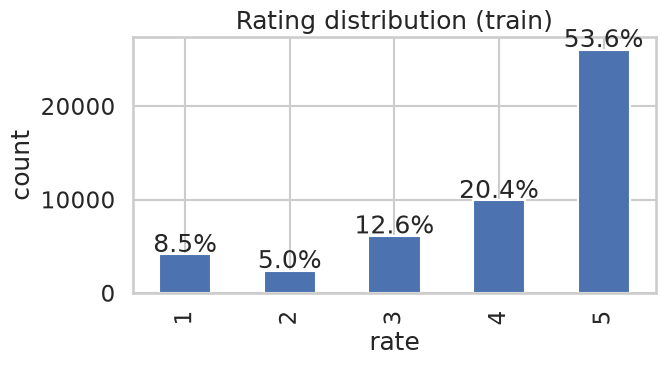

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
counts.plot(kind="bar", color="#4C72B0", ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + counts.max()*0.01, f"{pct.iloc[i]}%", ha="center")
ax.set_xlabel("rate"); ax.set_ylabel("count"); ax.set_title("Rating distribution (train)")
plt.tight_layout(); plt.savefig("../results/fig_class_balance.png", dpi=150); plt.show()

## Text length

In [5]:
tr_full["n_chars"] = tr_full["text"].str.len()
tr_full["n_words"] = tr_full["text"].str.split().map(len)
print(tr_full["n_chars"].describe().round(1))
g = tr_full.groupby("rate")[["n_chars", "n_words"]].agg(["mean", "median"]).round(1)
g

count    48665.0
mean       124.7
std        139.6
min          2.0
25%         45.0
50%         86.0
75%        156.0
max       3956.0
Name: n_chars, dtype: float64


n_chars        n_words       
        mean median    mean median
rate                              
1      233.4  155.0    35.4   23.0
2      181.7  131.0    27.4   19.0
3      147.0  104.0    21.9   15.0
4      121.3   90.0    17.6   13.0
5       98.2   73.0    13.7   10.0

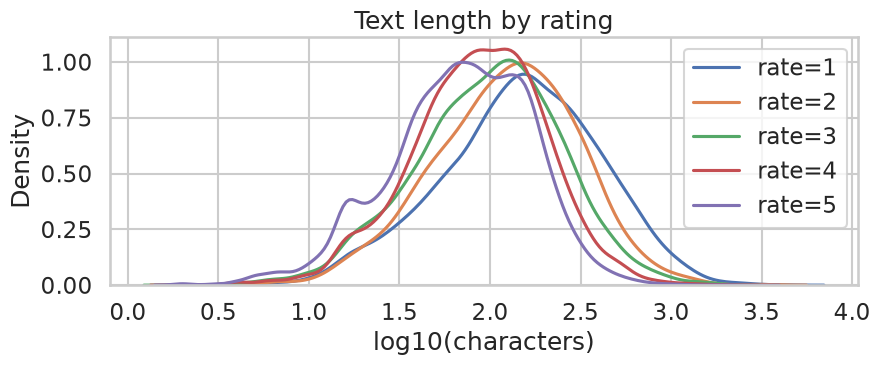

In [6]:
fig, ax = plt.subplots(figsize=(9, 4))
for r in sorted(tr_full["rate"].unique()):
    sns.kdeplot(np.log10(tr_full.loc[tr_full.rate == r, "n_chars"].clip(lower=1)), ax=ax, label=f"rate={r}", fill=False)
ax.set_xlabel("log10(characters)"); ax.set_title("Text length by rating"); ax.legend(); plt.tight_layout()
plt.savefig("../results/fig_length_by_rate.png", dpi=150); plt.show()

## Discriminative keywords (log-odds ratio with Dirichlet prior)

In [7]:
from collections import Counter
import re

def top_keywords(df, pos_rates=(5,), neg_rates=(1, 2), k=15, alpha=0.01):
    tok = re.compile(r"[А-Яа-яЁё]+")
    pos = Counter(); neg = Counter()
    for text, r in zip(df["text"], df["rate"]):
        words = [w.lower() for w in tok.findall(text) if len(w) >= 3]
        (pos if r in pos_rates else (neg if r in neg_rates else None)) and None
        if r in pos_rates: pos.update(words)
        elif r in neg_rates: neg.update(words)
    vocab = set(pos) | set(neg)
    Np, Nn = sum(pos.values()), sum(neg.values())
    scores = {}
    for w in vocab:
        p = (pos[w] + alpha) / (Np + alpha * len(vocab))
        n = (neg[w] + alpha) / (Nn + alpha * len(vocab))
        scores[w] = np.log(p / n)
    s = pd.Series(scores).sort_values()
    return s.head(k), s.tail(k)[::-1]

neg_top, pos_top = top_keywords(tr_full)
print("--- most POSITIVE words ---"); print(pos_top)
print("--- most NEGATIVE words ---"); print(neg_top)

--- most POSITIVE words ---
просторная      9.206554
пекарня         9.072250
топ             8.353850
доступно        8.186820
обожаю          8.156053
просторнее      7.825872
недорого        7.781430
современная     7.758446
преобразился    7.710829
компактный      7.660831
крутая          7.493824
ухоженный       7.463062
умеренные       7.463062
просрочек       7.431323
прохладно       7.398544
dtype: float64
--- most NEGATIVE words ---
худшая            -9.084736
отказалась        -8.614858
отстой            -8.614858
попросил          -8.614858
роспотребнадзор   -8.580968
худших            -8.545889
хамский           -8.391797
весах             -8.349256
мусор             -8.304824
половины          -8.258326
отказ             -8.258326
книгу             -8.209559
телефона          -8.158292
показывать        -8.158292
пыталась          -8.158292
dtype: float64


## Build and save the stratified split

In [8]:
sp = load_split(seed=RANDOM_STATE, val_frac=0.1)
print(f"train={len(sp.train)}  val={len(sp.val)}  test={len(sp.test)}")
sp.train.to_parquet("../data/train_split.parquet")
sp.val.to_parquet("../data/val_split.parquet")
sp.test.to_parquet("../data/test_full.parquet")
sp.train.groupby("label").size()

train=43801  val=4864  test=12167


label
0     3725
1     2169
2     5514
3     8930
4    23463
dtype: int64

### Notes

* Strong class imbalance — macro-F$_1$ is the right primary classification
  metric; `qwk` captures ordinal mistakes.
* 1-star reviews are shorter and more emotionally charged (we see
  concentrated negative lexicon). 5-star reviews are shortest.
* The split is produced by `stratified_split` in `src/data.py`; downstream
  notebooks load the parquet files so results are directly comparable.